In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (302, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (302, 13)
Target Shape: (302,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 241
Testing Samples: 61


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    print(name, "Training Completed")

Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
SVM Training Completed


C:\Users\mahir\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [7]:
np.random.seed(42)

input_size = X_train_scaled.shape[1]
hidden_size = 16
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def forward_pass(X):
    Z1 = X @ W1 + b1
    A1 = np.maximum(0, Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    return A1, A2

In [8]:
learning_rate = 0.01
epochs = 300

y_train_nn = y_train.reshape(-1, 1)

train_losses = []

for epoch in range(epochs):

    # Forward propagation
    A1, A2 = forward_pass(X_train_scaled)

    # Binary cross-entropy loss
    loss = -np.mean(
        y_train_nn * np.log(A2 + 1e-8) +
        (1 - y_train_nn) * np.log(1 - A2 + 1e-8)
    )

    train_losses.append(loss)

    # Backpropagation
    m = len(X_train_scaled)

    dZ2 = A2 - y_train_nn
    dW2 = (A1.T @ dZ2) / m
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (A1 > 0)

    dW1 = (X_train_scaled.T @ dZ1) / m
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Update weights
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss:.4f}")

Epoch 50/300, Loss: 0.6922
Epoch 100/300, Loss: 0.6913
Epoch 150/300, Loss: 0.6906
Epoch 200/300, Loss: 0.6899
Epoch 250/300, Loss: 0.6892
Epoch 300/300, Loss: 0.6884


In [9]:
_, train_probabilities = forward_pass(X_train_scaled)
_, test_probabilities = forward_pass(X_test_scaled)

y_train_dl = (train_probabilities.ravel() >= 0.5).astype(int)
y_test_dl = (test_probabilities.ravel() >= 0.5).astype(int)

print("Deep Learning Training Predictions:", y_train_dl[:10])
print("Deep Learning Testing Predictions:", y_test_dl[:10])

Deep Learning Training Predictions: [1 1 1 1 1 1 1 1 1 1]
Deep Learning Testing Predictions: [1 1 1 1 1 1 1 1 1 1]


In [10]:
def calculate_metrics(actual, predicted):

    TP = np.sum((actual == 1) & (predicted == 1))
    TN = np.sum((actual == 0) & (predicted == 0))
    FP = np.sum((actual == 0) & (predicted == 1))
    FN = np.sum((actual == 1) & (predicted == 0))

    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1_score
    }

In [11]:
results = []

for name, model in trained_models.items():

    train_predictions = model.predict(X_train_scaled)
    test_predictions = model.predict(X_test_scaled)

    train_metrics = calculate_metrics(y_train, train_predictions)
    test_metrics = calculate_metrics(y_test, test_predictions)

    results.append({
        "Model": name,
        "Train Accuracy": train_metrics["Accuracy"],
        "Test Accuracy": test_metrics["Accuracy"],
        "Test Precision": test_metrics["Precision"],
        "Test Recall": test_metrics["Recall"],
        "Test F1 Score": test_metrics["F1 Score"]
    })

dl_train_metrics = calculate_metrics(y_train, y_train_dl)
dl_test_metrics = calculate_metrics(y_test, y_test_dl)

results.append({
    "Model": "Deep Learning",
    "Train Accuracy": dl_train_metrics["Accuracy"],
    "Test Accuracy": dl_test_metrics["Accuracy"],
    "Test Precision": dl_test_metrics["Precision"],
    "Test Recall": dl_test_metrics["Recall"],
    "Test F1 Score": dl_test_metrics["F1 Score"]
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1 Score
0,Logistic Regression,0.8589,0.8033,0.8000,0.8485,0.8235
1,Decision Tree,0.9419,0.7705,0.8065,0.7576,0.7812
2,Random Forest,1.0000,0.7541,0.7647,0.7879,0.7761
3,SVM,0.9212,0.7705,0.7714,0.8182,0.7941
4,Deep Learning,0.5436,0.5410,0.5410,1.0000,0.7021


In [12]:
results_df["Overfitting Gap"] = (
    results_df["Train Accuracy"] - results_df["Test Accuracy"]
)

display(
    results_df[["Model", "Train Accuracy", "Test Accuracy", "Overfitting Gap"]]
    .round(4)
)

for _, row in results_df.iterrows():

    gap = row["Overfitting Gap"]

    if gap > 0.10:
        status = "High overfitting tendency"
    elif gap > 0.05:
        status = "Moderate overfitting tendency"
    else:
        status = "Low overfitting tendency"

    print(row["Model"], ":", status)

,Model,Train Accuracy,Test Accuracy,Overfitting Gap
0,Logistic Regression,0.8589,0.8033,0.0556
1,Decision Tree,0.9419,0.7705,0.1714
2,Random Forest,1.0000,0.7541,0.2459
3,SVM,0.9212,0.7705,0.1507
4,Deep Learning,0.5436,0.5410,0.0026


Logistic Regression : Moderate overfitting tendency
Decision Tree : High overfitting tendency
Random Forest : High overfitting tendency
SVM : High overfitting tendency
Deep Learning : Low overfitting tendency


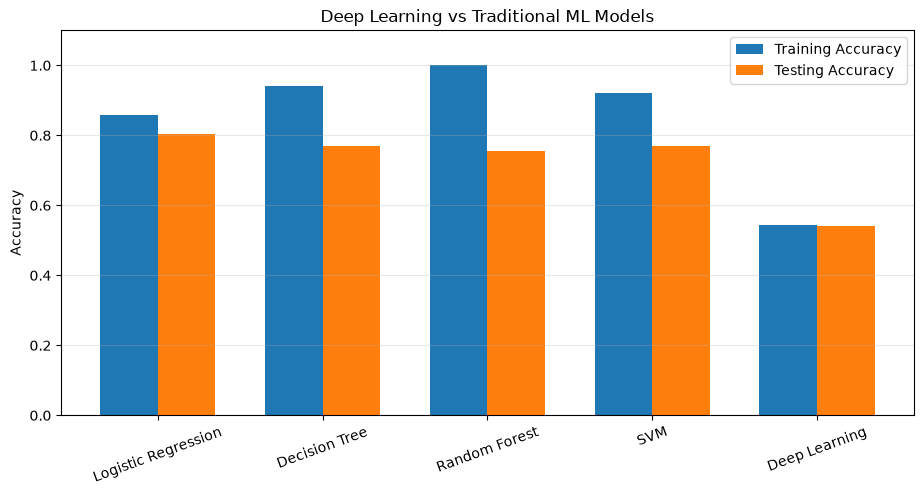

In [13]:
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width/2, results_df["Train Accuracy"], width, label="Training Accuracy")
plt.bar(x + width/2, results_df["Test Accuracy"], width, label="Testing Accuracy")

plt.xticks(x, results_df["Model"], rotation=20)
plt.ylabel("Accuracy")
plt.title("Deep Learning vs Traditional ML Models")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [14]:
best_model = results_df.loc[
    results_df["Test Accuracy"].idxmax(), "Model"
]

print("Best Performing Model:", best_model)

print("""
Conclusion:

Traditional Machine Learning models can perform effectively on structured
datasets such as heart disease prediction.

Deep Learning can learn complex patterns through hidden layers, but it
usually requires more data and computational resources.

Traditional ML models are generally easier to train, interpret, and deploy
on smaller datasets.

A large difference between training and testing accuracy may indicate
overfitting.

The best model should be selected by considering multiple evaluation
metrics, generalization performance, interpretability, and computational cost.
""")

Best Performing Model: Logistic Regression

Conclusion:

Traditional Machine Learning models can perform effectively on structured
datasets such as heart disease prediction.

Deep Learning can learn complex patterns through hidden layers, but it
usually requires more data and computational resources.

Traditional ML models are generally easier to train, interpret, and deploy
on smaller datasets.

A large difference between training and testing accuracy may indicate
overfitting.

The best model should be selected by considering multiple evaluation
metrics, generalization performance, interpretability, and computational cost.

